In [2]:
##Agrpamiento --> k-means

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df_final = pd.read_csv("../Práctica 1/glp1_limpio.csv", parse_dates=['FECHA'])

resumen_consultorio = df_final.groupby('PRACTICE_CODE').agg(
    revenue_total=('ACTUAL_COST', 'sum'),
    items_total=('ITEMS', 'sum'),
    meses_activo=('FECHA', 'nunique'),
    sustancias_distintas=('SUSTANCIA', 'nunique')
).reset_index()

resumen_consultorio['costo_promedio_receta'] = resumen_consultorio['revenue_total'] / resumen_consultorio['items_total']

resumen_consultorio.describe()

,revenue_total,items_total,meses_activo,sustancias_distintas,costo_promedio_receta
count,7.623000e+03,7623.000000,7623.000000,7623.000000,7623.000000
mean,2.001956e+05,1920.698413,54.977961,4.452971,107.717207
std,2.063943e+05,2019.754905,21.147308,1.250709,33.614877
min,9.892080e+00,1.000000,1.000000,1.000000,9.892080
25%,6.213838e+04,556.500000,65.000000,4.000000,91.373028
50%,1.478436e+05,1379.000000,65.000000,5.000000,102.536348
75%,2.769661e+05,2679.500000,65.000000,5.000000,117.851115
max,2.488317e+06,22775.000000,65.000000,6.000000,1104.012400


In [4]:
p1 = df_final[df_final['FECHA'].dt.year.isin([2021, 2022])]
p2 = df_final[df_final['FECHA'].dt.year.isin([2024, 2025])]

rev_p1 = p1.groupby('PRACTICE_CODE')['ACTUAL_COST'].sum().rename('rev_2021_2022')
rev_p2 = p2.groupby('PRACTICE_CODE')['ACTUAL_COST'].sum().rename('rev_2024_2025')

# solo consultorios que aparecen en AMBOS periodos
crecimiento = pd.concat([rev_p1, rev_p2], axis=1, join='inner')

crecimiento['crecimiento_pct'] = (
    (crecimiento['rev_2024_2025'] - crecimiento['rev_2021_2022']) / crecimiento['rev_2021_2022'] * 100
)

print(len(crecimiento))
crecimiento.describe()

6642


,rev_2021_2022,rev_2024_2025,crecimiento_pct
count,6642.000000,6.642000e+03,6642.000000
mean,56557.096183,9.888854e+04,146.230170
std,53580.606275,9.281764e+04,1387.502150
min,7.448550,1.842240e+01,-99.865350
25%,21993.774572,3.831531e+04,30.571475
50%,42686.486240,7.410072e+04,71.040248
75%,75092.690275,1.320926e+05,129.763896
max,736668.738770,1.077252e+06,98433.123242


In [5]:
# % del revenue de 2024-2025 que es Tirzepatide
rev_tirz = p2[p2['SUSTANCIA'] == 'Tirzepatide'].groupby('PRACTICE_CODE')['ACTUAL_COST'].sum()
crecimiento['pct_tirzepatide'] = (rev_tirz / crecimiento['rev_2024_2025']).fillna(0) * 100

crecimiento = crecimiento.reset_index()
datos = crecimiento.merge(
    resumen_consultorio[['PRACTICE_CODE', 'costo_promedio_receta']],
    on='PRACTICE_CODE'
)

vars_cluster = ['rev_2024_2025', 'crecimiento_pct', 'pct_tirzepatide', 'costo_promedio_receta']
print(len(datos))
print(datos[vars_cluster].quantile([0.5, 0.95, 0.99]).round(1))
print(datos[vars_cluster].corr().round(2))

6642
      rev_2024_2025  crecimiento_pct  pct_tirzepatide  costo_promedio_receta
0.50        74100.7             71.0             49.5                  103.2
0.95       271313.5            319.8             80.0                  145.1
0.99       442262.1            817.6             93.4                  171.9
                       rev_2024_2025  crecimiento_pct  pct_tirzepatide  \
rev_2024_2025                   1.00            -0.00             0.23   
crecimiento_pct                -0.00             1.00             0.09   
pct_tirzepatide                 0.23             0.09             1.00   
costo_promedio_receta           0.04             0.11             0.35   

                       costo_promedio_receta  
rev_2024_2025                           0.04  
crecimiento_pct                         0.11  
pct_tirzepatide                         0.35  
costo_promedio_receta                   1.00  


In [6]:
vars_recorte = ['rev_2024_2025', 'crecimiento_pct', 'costo_promedio_receta']
limites = datos[vars_recorte].quantile(0.99)

es_extremo = (datos[vars_recorte] > limites).any(axis=1)

extremos = datos[es_extremo]
datos_cluster = datos[~es_extremo].copy()

print("Excluidos:", len(extremos), f"({len(extremos)/len(datos)*100:.1f}%)")
print("Revenue 2024-2025 que concentran:",
      f"{extremos['rev_2024_2025'].sum() / datos['rev_2024_2025'].sum() * 100:.1f}%")
print("Quedan:", len(datos_cluster))

Excluidos: 187 (2.8%)
Revenue 2024-2025 que concentran: 6.7%
Quedan: 6455


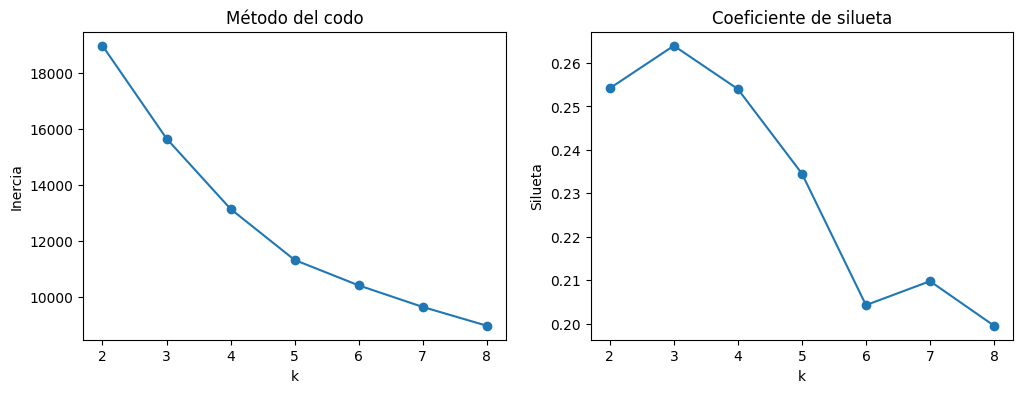

In [7]:
%matplotlib inline
vars_cluster = ['rev_2024_2025', 'crecimiento_pct', 'pct_tirzepatide', 'costo_promedio_receta']

scaler = StandardScaler()
X = scaler.fit_transform(datos_cluster[vars_cluster])

inercias = []
silhouettes = []
rango_k = range(2, 9)

for k in rango_k:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = modelo.fit_predict(X)
    inercias.append(modelo.inertia_)
    silhouettes.append(silhouette_score(X, etiquetas))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(rango_k, inercias, marker='o')
axes[0].set_title('Método del codo')
axes[0].set_xlabel('k')
axes[0].set_ylabel('Inercia')
axes[1].plot(rango_k, silhouettes, marker='o')
axes[1].set_title('Coeficiente de silueta')
axes[1].set_xlabel('k')
axes[1].set_ylabel('Silueta')
plt.show()

In [8]:
k_elegido = 4 

modelo_final = KMeans(n_clusters=k_elegido, random_state=42, n_init=10)
datos_cluster['cluster'] = modelo_final.fit_predict(X)

datos_cluster['crecimiento_abs'] = datos_cluster['rev_2024_2025'] - datos_cluster['rev_2021_2022']

perfil = datos_cluster.groupby('cluster').agg(
    n_consultorios=('PRACTICE_CODE', 'count'),
    rev_2024_2025_medio=('rev_2024_2025', 'mean'),
    crecimiento_pct_mediano=('crecimiento_pct', 'median'),
    pct_tirzepatide_medio=('pct_tirzepatide', 'mean'),
    costo_receta_medio=('costo_promedio_receta', 'mean'),
    crecimiento_abs_total=('crecimiento_abs', 'sum')
).round(1)

perfil['pct_consultorios'] = (perfil['n_consultorios'] / perfil['n_consultorios'].sum() * 100).round(1)
perfil['pct_del_crecimiento_total'] = (perfil['crecimiento_abs_total'] / perfil['crecimiento_abs_total'].sum() * 100).round(1)

perfil_4 = perfil.copy()
perfil

,n_consultorios,rev_2024_2025_medio,crecimiento_pct_mediano,pct_tirzepatide_medio,costo_receta_medio,crecimiento_abs_total,pct_consultorios,pct_del_crecimiento_total
cluster,,,,,,,,
0,2438,61762.3,36.4,30.7,93.0,36916976.1,37.8,14.3
1,1182,222897.4,94.1,57.7,105.3,124066879.4,18.3,48.1
2,2369,67867.8,80.2,57.6,116.9,67868165.6,36.7,26.3
3,466,81815.8,321.0,61.6,119.5,29174596.1,7.2,11.3


In [9]:
perfil['crecimiento_por_consultorio'] = (perfil['crecimiento_abs_total'] / perfil['n_consultorios']).round(0)
perfil[['n_consultorios', 'rev_2024_2025_medio', 'crecimiento_por_consultorio']]

,n_consultorios,rev_2024_2025_medio,crecimiento_por_consultorio
cluster,,,
0,2438,61762.3,15142.0
1,1182,222897.4,104964.0
2,2369,67867.8,28648.0
3,466,81815.8,62606.0


In [10]:
perfil['aporte_vs_peso'] = (perfil['pct_del_crecimiento_total'] / perfil['pct_consultorios']).round(2)
perfil['rev_2021_2022_medio_aprox'] = (perfil['rev_2024_2025_medio'] - perfil['crecimiento_por_consultorio']).round(0)
perfil[['pct_consultorios', 'pct_del_crecimiento_total', 'aporte_vs_peso', 'rev_2021_2022_medio_aprox']]

,pct_consultorios,pct_del_crecimiento_total,aporte_vs_peso,rev_2021_2022_medio_aprox
cluster,,,,
0,37.8,14.3,0.38,46620.0
1,18.3,48.1,2.63,117933.0
2,36.7,26.3,0.72,39220.0
3,7.2,11.3,1.57,19210.0


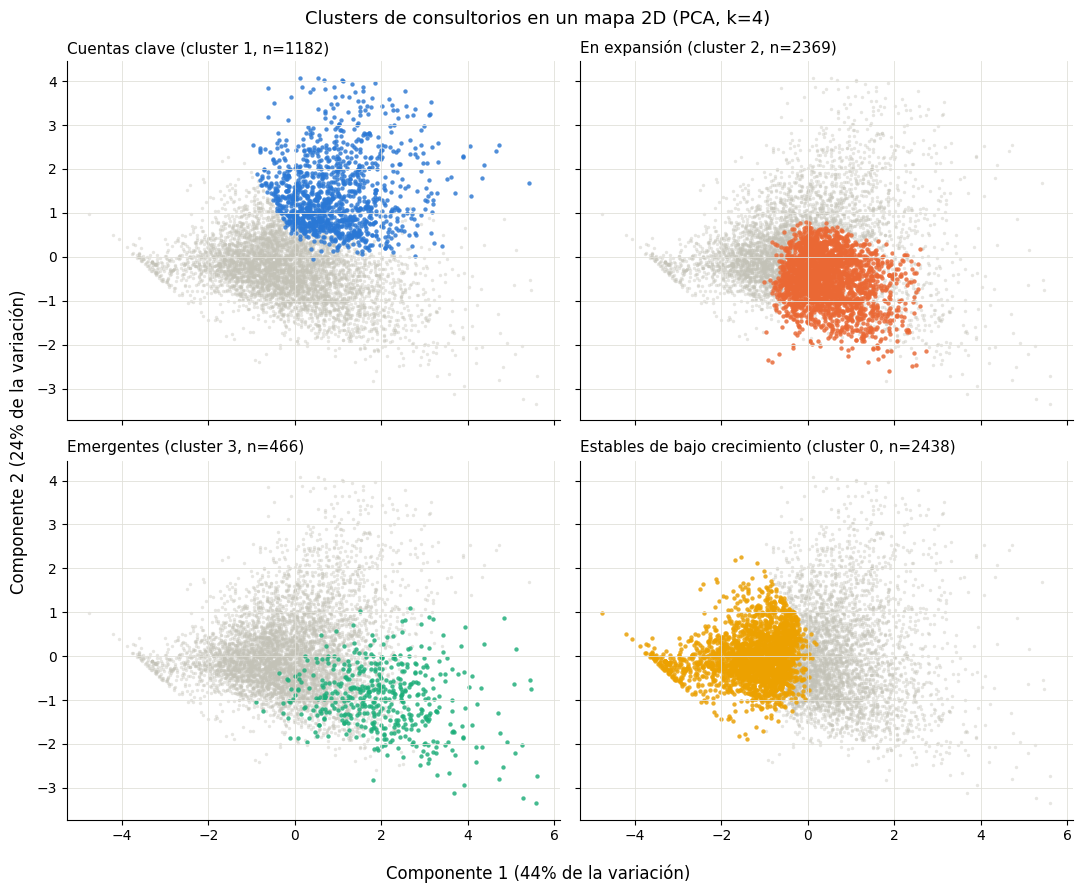

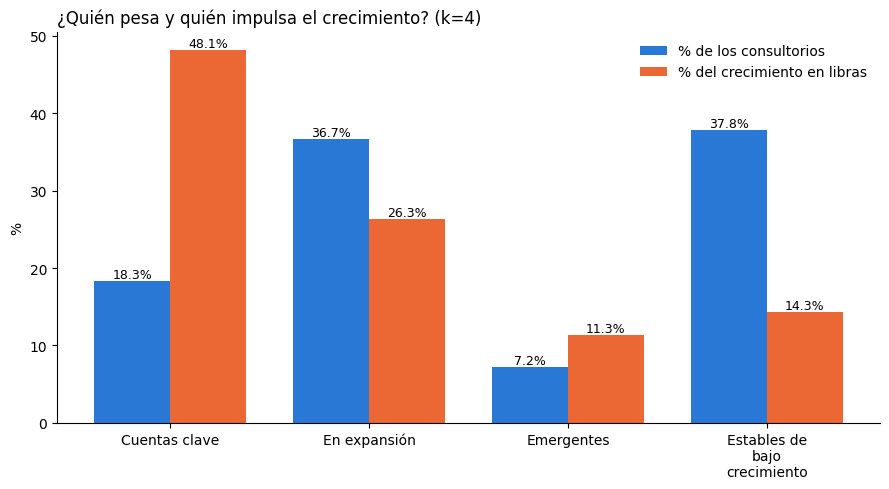

In [11]:
import textwrap
from sklearn.decomposition import PCA

nombres = {1: 'Cuentas clave', 2: 'En expansión', 3: 'Emergentes', 0: 'Estables de bajo crecimiento'}
colores = {1: '#2a78d6', 2: '#eb6834', 3: '#1baf7a', 0: '#eda100'}

# --- Gráfica 1: mapa 2D por cluster ---
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X)
datos_cluster['pc1'] = coords[:, 0]
datos_cluster['pc2'] = coords[:, 1]
var_exp = pca.explained_variance_ratio_ * 100

fig, axes = plt.subplots(2, 2, figsize=(11, 9), sharex=True, sharey=True)
for ax, c in zip(axes.flat, [1, 2, 3, 0]):
    ax.scatter(datos_cluster['pc1'], datos_cluster['pc2'], s=6, color='#c3c2b7', alpha=0.4, linewidths=0)
    sub = datos_cluster[datos_cluster['cluster'] == c]
    ax.scatter(sub['pc1'], sub['pc2'], s=10, color=colores[c], alpha=0.8, linewidths=0)
    ax.set_title(f"{nombres[c]} (cluster {c}, n={len(sub)})", fontsize=11, loc='left')
    ax.grid(color='#e1e0d9', linewidth=0.6)
    for lado in ['top', 'right']:
        ax.spines[lado].set_visible(False)
fig.supxlabel(f"Componente 1 ({var_exp[0]:.0f}% de la variación)")
fig.supylabel(f"Componente 2 ({var_exp[1]:.0f}% de la variación)")
fig.suptitle("Clusters de consultorios en un mapa 2D (PCA, k=4)", fontsize=13)
plt.tight_layout()
plt.show()

# --- Gráfica 2: peso vs aporte al crecimiento ---
orden = [1, 2, 3, 0]
etiquetas = [textwrap.fill(nombres[c], 14) for c in orden]
peso = perfil.loc[orden, 'pct_consultorios']
aporte = perfil.loc[orden, 'pct_del_crecimiento_total']

x = np.arange(len(orden))
w = 0.38
fig, ax = plt.subplots(figsize=(9, 5))
b1 = ax.bar(x - w/2, peso, w, color='#2a78d6', label='% de los consultorios')
b2 = ax.bar(x + w/2, aporte, w, color='#eb6834', label='% del crecimiento en libras')
ax.bar_label(b1, fmt='%.1f%%', fontsize=9)
ax.bar_label(b2, fmt='%.1f%%', fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(etiquetas)
ax.set_ylabel('%')
ax.set_title('¿Quién pesa y quién impulsa el crecimiento? (k=4)', loc='left')
ax.legend(frameon=False)
for lado in ['top', 'right']:
    ax.spines[lado].set_visible(False)
plt.tight_layout()
plt.show()

In [12]:
extremos = extremos.copy()
extremos['crecimiento_abs'] = extremos['rev_2024_2025'] - extremos['rev_2021_2022']

crec_total_todos = (datos['rev_2024_2025'] - datos['rev_2021_2022']).sum()
print("Aporte de los excluidos al crecimiento total:",
      round(extremos['crecimiento_abs'].sum() / crec_total_todos * 100, 1), "%")

# ¿En qué cluster caerían? (mismo scaler y mismo modelo)
X_ext = scaler.transform(extremos[vars_cluster])
extremos['cluster'] = modelo_final.predict(X_ext)
print(extremos['cluster'].map(nombres).value_counts())

Aporte de los excluidos al crecimiento total: 8.2 %
cluster
Emergentes       88
Cuentas clave    65
En expansión     34
Name: count, dtype: int64


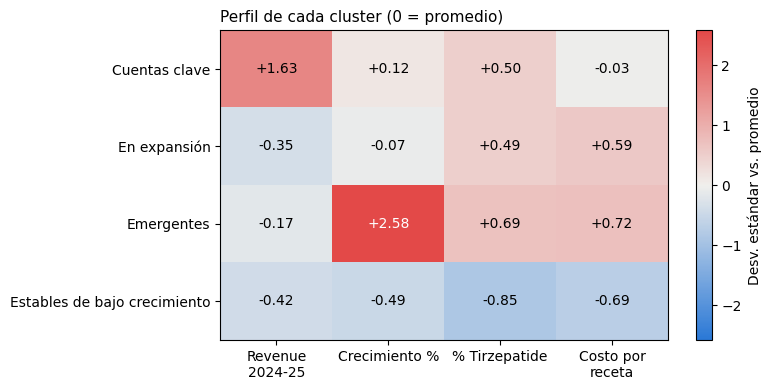

In [13]:
from matplotlib.colors import LinearSegmentedColormap

centros = pd.DataFrame(modelo_final.cluster_centers_, columns=vars_cluster)
centros.index = [nombres[i] for i in centros.index]
centros = centros.loc[['Cuentas clave', 'En expansión', 'Emergentes', 'Estables de bajo crecimiento']]
etq_cols = ['Revenue\n2024-25', 'Crecimiento %', '% Tirzepatide', 'Costo por\nreceta']

cmap = LinearSegmentedColormap.from_list('div', ['#2a78d6', '#f0efec', '#e34948'])
lim = np.abs(centros.values).max()

fig, ax = plt.subplots(figsize=(8, 4))
im = ax.imshow(centros.values, cmap=cmap, vmin=-lim, vmax=lim, aspect='auto')
ax.set_xticks(range(len(etq_cols)))
ax.set_xticklabels(etq_cols)
ax.set_yticks(range(len(centros)))
ax.set_yticklabels(centros.index)
for i in range(centros.shape[0]):
    for j in range(centros.shape[1]):
        v = centros.values[i, j]
        ax.text(j, i, f"{v:+.2f}", ha='center', va='center', fontsize=10,
                color='white' if abs(v) > 0.7 * lim else 'black')
cbar = fig.colorbar(im, ax=ax)
ax.set_title('Perfil de cada cluster (0 = promedio)', loc='left', fontsize=11)
cbar.set_label('Desv. estándar vs. promedio')
plt.tight_layout()
plt.show()

In [14]:
modelo_5 = KMeans(n_clusters=5, random_state=42, n_init=10)
datos_cluster['cluster_5'] = modelo_5.fit_predict(X)

perfil_5 = datos_cluster.groupby('cluster_5').agg(
    n_consultorios=('PRACTICE_CODE', 'count'),
    rev_2024_2025_medio=('rev_2024_2025', 'mean'),
    crecimiento_pct_mediano=('crecimiento_pct', 'median'),
    pct_tirzepatide_medio=('pct_tirzepatide', 'mean'),
    costo_receta_medio=('costo_promedio_receta', 'mean'),
    crecimiento_abs_total=('crecimiento_abs', 'sum')
).round(1)
perfil_5['pct_consultorios'] = (perfil_5['n_consultorios'] / perfil_5['n_consultorios'].sum() * 100).round(1)
perfil_5['pct_del_crecimiento_total'] = (perfil_5['crecimiento_abs_total'] / perfil_5['crecimiento_abs_total'].sum() * 100).round(1)
print(perfil_5)

# ¿Cómo se reparten los segmentos del k=4 dentro del k=5?
print(pd.crosstab(datos_cluster['cluster'], datos_cluster['cluster_5']))

           n_consultorios  rev_2024_2025_medio  crecimiento_pct_mediano  \
cluster_5                                                                 
0                    1759              57637.6                     30.9   
1                    1180              73610.2                     85.0   
2                    2152              76852.9                     67.9   
3                     441              80636.6                    328.7   
4                     923             242419.7                     99.1   

           pct_tirzepatide_medio  costo_receta_medio  crecimiento_abs_total  \
cluster_5                                                                     
0                           24.6                92.4             21719596.0   
1                           53.0               132.0             38704179.4   
2                           56.7               100.3             62890029.1   
3                           62.1               118.2             27358045.0   


In [15]:
# región de cada consultorio (asume que no cambia de región)
region_por_consultorio = (
    df_final[['PRACTICE_CODE', 'REGIONAL_OFFICE_NAME']]
    .drop_duplicates('PRACTICE_CODE')
    .set_index('PRACTICE_CODE')['REGIONAL_OFFICE_NAME']
)
datos_cluster['region'] = datos_cluster['PRACTICE_CODE'].map(region_por_consultorio)

orden_nombres = ['Cuentas clave', 'En expansión', 'Emergentes', 'Estables de bajo crecimiento']
segmento = datos_cluster['cluster'].map(nombres)

cruce = (pd.crosstab(datos_cluster['region'], segmento, normalize='index') * 100)[orden_nombres].round(1)
print(cruce)

print("\nReparto general (todas las regiones):")
print((segmento.value_counts(normalize=True)[orden_nombres] * 100).round(1))

cluster                   Cuentas clave  En expansión  Emergentes  \
region                                                              
EAST OF ENGLAND                    23.1          28.8         5.9   
LONDON                              6.8          53.9         9.7   
MIDLANDS                           20.0          36.6         5.7   
NORTH EAST AND YORKSHIRE           18.0          29.0         9.7   
NORTH WEST                         15.7          27.6         5.1   
SOUTH EAST                         28.8          38.9         6.6   
SOUTH WEST                         22.5          37.7         7.6   

cluster                   Estables de bajo crecimiento  
region                                                  
EAST OF ENGLAND                                   42.1  
LONDON                                            29.6  
MIDLANDS                                          37.7  
NORTH EAST AND YORKSHIRE                          43.2  
NORTH WEST                          

In [16]:
print(inercias) 
print(silhouettes)

[18960.74279250943, 15654.844517461073, 13147.948336013433, 11331.763620016409, 10427.424529327853, 9659.163551385485, 8990.599952565291]
[0.2541693579045058, 0.26396494900344314, 0.25399541963948785, 0.23454307414456088, 0.2042795472693547, 0.20978229382142083, 0.19953700386209516]


In [17]:
(datos_cluster[['PRACTICE_CODE', 'cluster']]
 .assign(segmento=datos_cluster['cluster'].map(nombres))
 [['PRACTICE_CODE', 'segmento']]
 .to_csv('segmentos_p7.csv', index=False))